# Final Project: SEP Tutorial with Astropy


In [20]:
# importing libraries 
import numpy as np 
import sep 
import matplotlib.pyplot as plt
from astropy.io import fits 
from matplotlib.patches import Ellipse
from matplotlib import rcParams
%matplotlib inline



In [21]:
# Setup for inline plotting and figure size 
rcParams['figure.figsize'] = [10.,8.]

# Step 1: Loading FITS image using astropy.io.fits

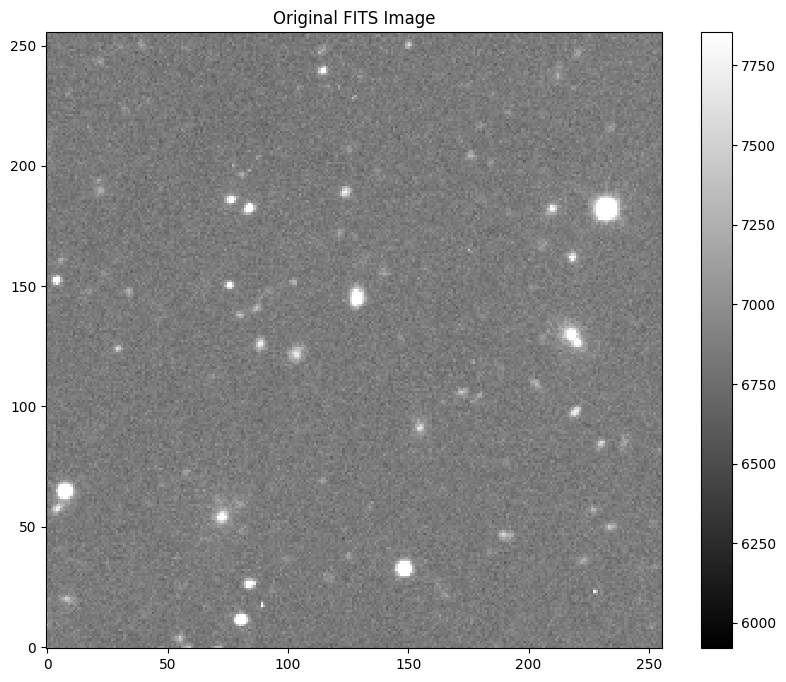

[[6674.401  6785.465  6963.752  6835.1514 7004.6704]
 [6803.0015 6858.533  6808.8467 6925.7563 6914.0654]
 [6890.6836 6753.315  6820.538  6840.997  6870.2246]
 [6814.6924 6838.074  6925.7563 6776.697  6957.9062]
 [6770.8516 6896.5293 6952.061  6978.3657 6776.697 ]]


In [22]:
with fits.open('image.fits') as hdul:
    data = hdul[0].data

    # Only swap bytes if it's non-native (usually big-endian)
    if not data.dtype.isnative:
        print("Swapping byte order...")
        data = data.byteswap().newbyteorder()

    data = data.astype(np.float32)
# Display the original image and save
m, s = np.mean(data), np.std(data)
plt.imshow(data, interpolation='nearest', cmap='gray', vmin=m-s, vmax=m+s, origin='lower')
plt.colorbar()
plt.title("Original FITS Image")
plt.savefig("figure1_original_image.png")
plt.show()
print(data[100:105, 100:105])

## Background Subtraction 

Most optical/IR images require background subtraction before sources can be detected. SEP seperates 
background estimation and source extraction. In this section, we meaasure and subtract the background  from the image using 'sep.background'.

In [23]:
# estimate a spatially varying background 
bkg = sep.Background(data)

Global background value: 6852.04931640625
Global RMS: 65.46174621582031


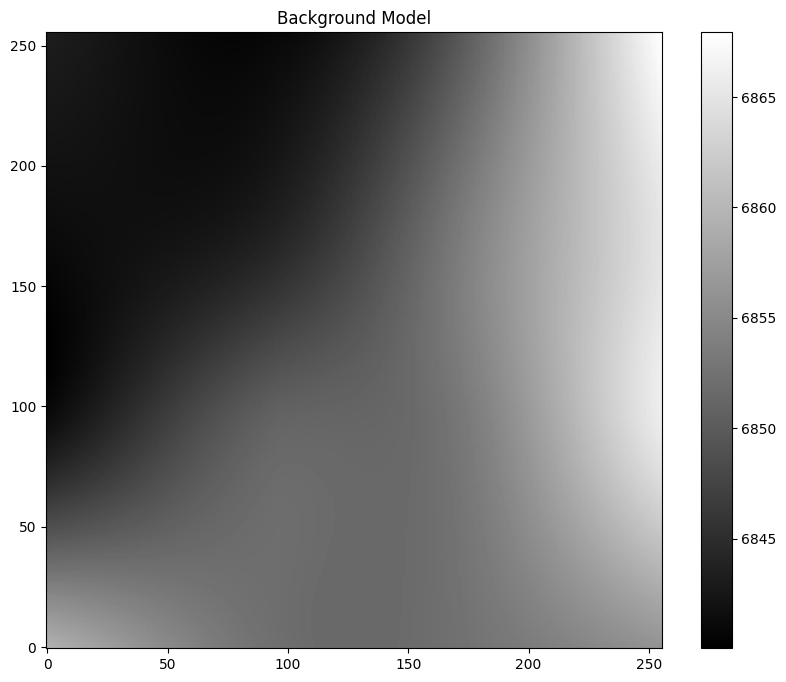

In [24]:
# print global background stats 
print("Global background value:", bkg.globalback)
print("Global RMS:", bkg.globalrms)

# Evaluate the 2D background model 
bkg_image = bkg.back()

# Display background image 
plt.imshow(bkg_image, interpolation='nearest', cmap='gray', origin='lower')
plt.colorbar()
plt.title("Background Model")
plt.savefig("figure2_background_model.png")
plt.show()

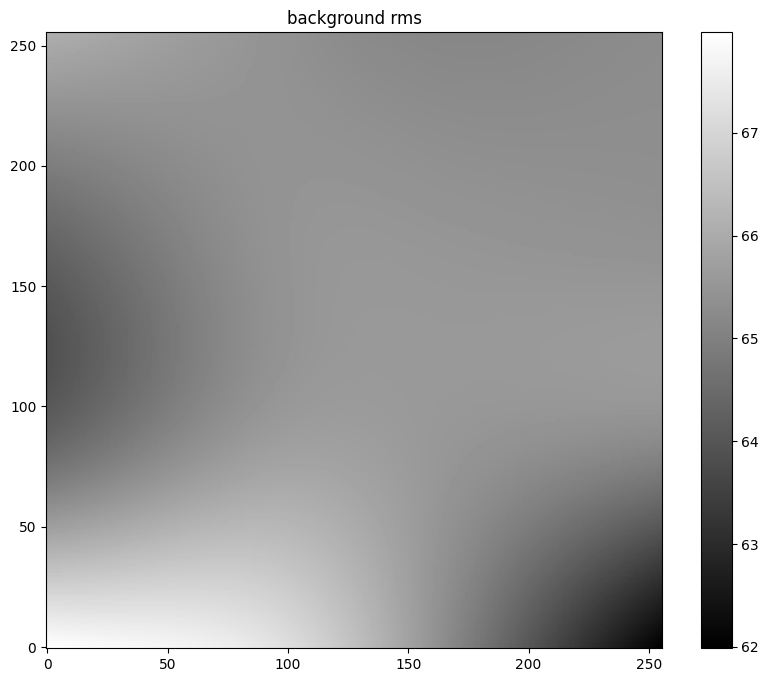

In [25]:
# Evaluate background RMS noise 
bkg_rms = bkg.rms()

# Display background RMS image 
plt.imshow(bkg_rms, interpolation='nearest', cmap='gray', origin='lower')
plt.colorbar()
plt.title("background rms")
plt.savefig("figure3_background_rms.png") 
plt.show()

In [26]:
# Subtract background from original image 
data_sub = data - bkg

> **Warning:** If the data is not background-subtracted or if the detection threshold is too low, `sep.extract` may detect one massive object or raise a memory error. Always subtract the background before extracting sources.


### Object Detection

Now that we subtracted the background, we can detect objects in the image using `sep.extract`. This function identifies connected regions above a given threshold. Here, we set the threshold to `1.5 × global background RMS`.

The result is a NumPy structured array, with fields for object positions, shape parameters, and more.


In [27]:
# Detect objects in the background-subtracted image 

objects = sep.extract(data_sub, thresh=1.5, err=bkg.globalrms)

# print number of objects detected 

print("Number of object detected:", len(objects))

Number of object detected: 68


Each object contains centroid coordinates, shape parameters, and other metadata. We'll now plot ellipses representing each detected object on top of the image to visualize the detections.


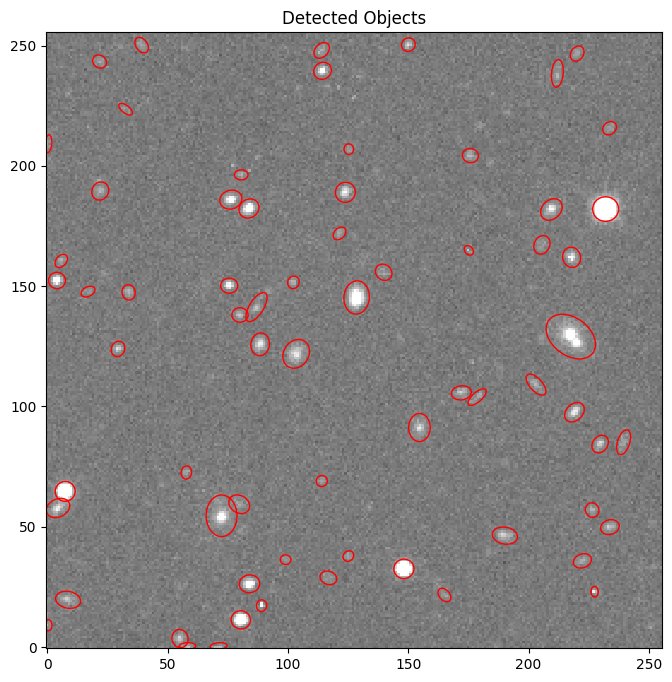

In [28]:
# Plot the detected objects on the image
fig, ax = plt.subplots()
m, s = np.mean(data_sub), np.std(data_sub)

# Display background-subtracted image
ax.imshow(data_sub, interpolation='nearest', cmap='gray',
          vmin=m-s, vmax=m+s, origin='lower')

# Overlay ellipses for each object
for i in range(len(objects)):
    e = Ellipse(xy=(objects['x'][i], objects['y'][i]),
                width=6*objects['a'][i],
                height=6*objects['b'][i],
                angle=objects['theta'][i] * 180. / np.pi)
    e.set_facecolor('none')
    e.set_edgecolor('red')
    ax.add_artist(e)

ax.set_title("Detected Objects")
plt.savefig("figure4_detected_objects.png")
plt.show()


### Aperture Photometry

We now measure the flux of each detected object using circular aperture photometry with a radius of 3 pixels. The function `sep.sum_circle` returns the total flux, its uncertainty, and flags for each object.


In [32]:
# Perform circular aperture photometry at object positions
flux, fluxerr, flag = sep.sum_circle(
    data_sub, objects['x'], objects['y'],
    3.0, err=bkg.globalrms, gain=1.0
)


Below are the fluxes and uncertainties for the first 10 detected objects.


In [33]:
# Show results for the first 10 objects
for i in range(min(10, len(flux))):
    print("Object {:d}: flux = {:f} +/- {:f}".format(i, flux[i], fluxerr[i]))


Object 0: flux = 2249.159297 +/- 291.027802
Object 1: flux = 3092.220430 +/- 291.592204
Object 2: flux = 5949.868379 +/- 356.562003
Object 3: flux = 1851.426582 +/- 295.028816
Object 4: flux = 72736.386914 +/- 440.172206
Object 5: flux = 3860.756152 +/- 352.163162
Object 6: flux = 6418.913789 +/- 357.458973
Object 7: flux = 2210.707656 +/- 350.791223
Object 8: flux = 2741.607227 +/- 352.277746
Object 9: flux = 20916.875566 +/- 376.966138


To understand the distribution of detected object brightness, we plot a histogram of the flux values below.


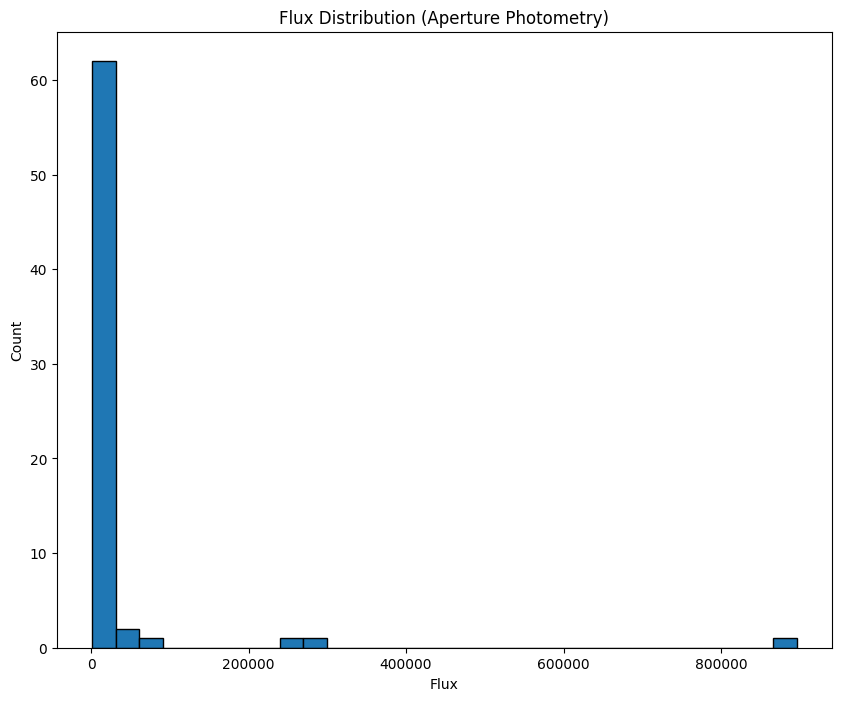

In [35]:
plt.hist(flux, bins=30, edgecolor='black')
plt.title("Flux Distribution (Aperture Photometry)")
plt.xlabel("Flux")
plt.ylabel("Count")
plt.savefig("figure5_flux_histogram.png")
plt.show()
